# Does changing the machine-learning algorithm improve building-age classification, even when the input features remain unchanged?


In [1]:
import pickle
import numpy as np
import pandas as pd

# Load the existing preprocessed dataset
with open('./data/preprocessed/Preprocessed_data.pkl', 'rb') as f:
    data = pickle.load(f)

# Extract Madrid data (source city)
X_madrid = data['X_madrid']
y_madrid = data['y_madrid']
pixel_ids_madrid = data['pixel_ids_madrid']

# Extract Amsterdam data (target city)
X_amsterdam = data['X_amsterdam']
y_amsterdam = data['y_amsterdam']
pixel_ids_amsterdam = data['pixel_ids_amsterdam']

# Extract feature names
feature_names = data['feature_names']

print("Preprocessed dataset loaded successfully!")

Preprocessed dataset loaded successfully!


In [2]:

print("\nAMSTERDAM (TARGET CITY)")
print("Features:", X_amsterdam.shape)
print("Labels:", y_amsterdam.shape)
print("Unique pixels:", len(pixel_ids_amsterdam))

print("\nFEATURE INFORMATION")
print("Number of features:", len(feature_names))
print("Age classes:", sorted(pd.Series(y_madrid).unique()))

# Check missing values in both datasets
print("\nMISSING VALUES")

print("Madrid:", np.isnan(X_madrid).sum())
print("Amsterdam:", np.isnan(X_amsterdam).sum())

# Check infinite values
print("\nINFINITE VALUES")

print("Madrid:", np.isinf(X_madrid).sum())
print("Amsterdam:", np.isinf(X_amsterdam).sum())


AMSTERDAM (TARGET CITY)
Features: (25992, 92)
Labels: (25992,)
Unique pixels: 25992

FEATURE INFORMATION
Number of features: 92
Age classes: [np.int64(1), np.int64(2), np.int64(3), np.int64(4)]

MISSING VALUES
Madrid: 0
Amsterdam: 0

INFINITE VALUES
Madrid: 0
Amsterdam: 0


Step 4: Import Extra Trees
Now let's prepare our first algorithm.


In [3]:
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    f1_score
)

# Set random seed
RANDOM_STATE = 42

print("Extra Trees libraries imported successfully!")

Extra Trees libraries imported successfully!


# Step 5: Configure the Extra Trees model
We will initially use 500 trees, matching the number of trees in our Random Forest baseline.

In [4]:
# Configure Extra Trees
extra_trees_model = ExtraTreesClassifier(
    n_estimators=800,
    class_weight='balanced',
    random_state=RANDOM_STATE,
    n_jobs=-1
)

print("Extra Trees model configured successfully!")
print(extra_trees_model)


Extra Trees model configured successfully!
ExtraTreesClassifier(class_weight='balanced', n_estimators=800, n_jobs=-1,
                     random_state=42)


# Step 6: Evaluate Extra Trees on Madrid
First, we need to establish how well the model performs in its source city before testing transfer to Amsterdam.

We will use Repeated Stratified 5-Fold Cross-Validation, repeated 5 times.

This means:
- The Madrid dataset is divided into 5 folds.
- The model trains on 4 folds and tests on the remaining fold.
- This process repeats until every fold has been used for testing.
- The entire process is repeated 5 times using different splits.
- We calculate the macro F1-score for each run.

In [6]:
# Configure cross-validation
cv = RepeatedStratifiedKFold(
    n_splits=5,
    n_repeats=5,
    random_state=RANDOM_STATE
)

# Evaluate Extra Trees using macro F1
extra_trees_scores = cross_val_score(
    extra_trees_model,
    X_madrid,
    y_madrid,
    cv=cv,
    scoring='f1_macro',
    n_jobs=1
)

# Display results
print("EXTRA TREES - MADRID CROSS-VALIDATION")
print("--------------------------------------")

print("Number of evaluations:", len(extra_trees_scores))
print("Individual F1 scores:", np.round(extra_trees_scores, 4))

print("\nMean Macro F1:", round(extra_trees_scores.mean(), 4))
print("Standard Deviation:", round(extra_trees_scores.std(), 4))

EXTRA TREES - MADRID CROSS-VALIDATION
--------------------------------------
Number of evaluations: 25
Individual F1 scores: [0.6308 0.6367 0.6364 0.6321 0.6263 0.6289 0.6369 0.6406 0.6272 0.6258
 0.625  0.6354 0.6308 0.6367 0.63   0.6362 0.6299 0.629  0.635  0.632
 0.6339 0.6308 0.6327 0.6318 0.6324]

Mean Macro F1: 0.6321
Standard Deviation: 0.0039


In [7]:
# Configure 5-fold x 5-repeat cross-validation
cv = RepeatedStratifiedKFold(
    n_splits=5,
    n_repeats=5,
    random_state=RANDOM_STATE
)

extra_trees_scores = []

print("5-fold x 5-repeat CV on Madrid  (25 model fits)")
print("-" * 63)

# Train and evaluate each fold
for fit_number, (train_idx, test_idx) in enumerate(
    cv.split(X_madrid, y_madrid), start=1
):
    X_train, X_test = X_madrid[train_idx], X_madrid[test_idx]
    y_train, y_test = y_madrid[train_idx], y_madrid[test_idx]

    # Train model
    extra_trees_model.fit(X_train, y_train)

    # Predict validation fold
    y_pred = extra_trees_model.predict(X_test)

    # Calculate macro F1
    score = f1_score(y_test, y_pred, average='macro')
    extra_trees_scores.append(score)

    print(f"  Fit {fit_number:2d}/25: macro-F1 = {score:.4f}")

# Calculate summary statistics
mean_f1 = np.mean(extra_trees_scores)
std_f1 = np.std(extra_trees_scores)

print("-" * 63)
print(f"  Mean macro F1: {mean_f1:.4f} +/- {std_f1:.4f}")

5-fold x 5-repeat CV on Madrid  (25 model fits)
---------------------------------------------------------------
  Fit  1/25: macro-F1 = 0.6308
  Fit  2/25: macro-F1 = 0.6367
  Fit  3/25: macro-F1 = 0.6364
  Fit  4/25: macro-F1 = 0.6321
  Fit  5/25: macro-F1 = 0.6263
  Fit  6/25: macro-F1 = 0.6289
  Fit  7/25: macro-F1 = 0.6369
  Fit  8/25: macro-F1 = 0.6406
  Fit  9/25: macro-F1 = 0.6272
  Fit 10/25: macro-F1 = 0.6258
  Fit 11/25: macro-F1 = 0.6250
  Fit 12/25: macro-F1 = 0.6354
  Fit 13/25: macro-F1 = 0.6308
  Fit 14/25: macro-F1 = 0.6367
  Fit 15/25: macro-F1 = 0.6300
  Fit 16/25: macro-F1 = 0.6362
  Fit 17/25: macro-F1 = 0.6299
  Fit 18/25: macro-F1 = 0.6290
  Fit 19/25: macro-F1 = 0.6350
  Fit 20/25: macro-F1 = 0.6320
  Fit 21/25: macro-F1 = 0.6339
  Fit 22/25: macro-F1 = 0.6308
  Fit 23/25: macro-F1 = 0.6327
  Fit 24/25: macro-F1 = 0.6318
  Fit 25/25: macro-F1 = 0.6324
---------------------------------------------------------------
  Mean macro F1: 0.6321 +/- 0.0039


# Next: Train Extra Trees on all Madrid data
We need a final model trained on the complete Madrid dataset before evaluating it on Amsterdam.

In [8]:
# Train Extra Trees using all Madrid data
extra_trees_final = ExtraTreesClassifier(
    n_estimators=500,
    class_weight='balanced',
    random_state=RANDOM_STATE,
    n_jobs=-1
)

extra_trees_final.fit(X_madrid, y_madrid)

print("Final Extra Trees model trained successfully!")
print("Training samples:", len(y_madrid))
print("Number of features:", X_madrid.shape[1])

Final Extra Trees model trained successfully!
Training samples: 76263
Number of features: 92


# Step 7: Zero-shot transfer to Amsterdam
Now we test whether the model can recognise building-age patterns in Amsterdam without receiving any Amsterdam training examples.

In [9]:
# Predict Amsterdam using the Madrid-trained Extra Trees model
y_pred_ams_et = extra_trees_final.predict(X_amsterdam)

# Calculate evaluation metrics
et_zero_shot_f1 = f1_score(
    y_amsterdam,
    y_pred_ams_et,
    average='macro'
)

et_zero_shot_accuracy = accuracy_score(
    y_amsterdam,
    y_pred_ams_et
)

print("EXTRA TREES - AMSTERDAM ZERO-SHOT EVALUATION")
print("-" * 55)

print(f"Macro F1: {et_zero_shot_f1:.4f}")
print(f"Accuracy: {et_zero_shot_accuracy:.4f}")

EXTRA TREES - AMSTERDAM ZERO-SHOT EVALUATION
-------------------------------------------------------
Macro F1: 0.4772
Accuracy: 0.4923


# Step 8: Examine Extra Trees classification performance
Before few-shot experiments, let's understand which building-age classes Extra Trees predicts well and which ones it struggles with. 

In [10]:
print("EXTRA TREES - AMSTERDAM CLASSIFICATION REPORT")
print("-" * 55)

print(classification_report(
    y_amsterdam,
    y_pred_ams_et,
    digits=4
))

print("\nCONFUSION MATRIX")

print(confusion_matrix(
    y_amsterdam,
    y_pred_ams_et
))

EXTRA TREES - AMSTERDAM CLASSIFICATION REPORT
-------------------------------------------------------
              precision    recall  f1-score   support

           1     0.5919    0.3634    0.4503      7568
           2     0.4132    0.7941    0.5436      8802
           3     0.8230    0.2302    0.3598      6745
           4     0.5912    0.5228    0.5549      2877

    accuracy                         0.4923     25992
   macro avg     0.6048    0.4776    0.4772     25992
weighted avg     0.5913    0.4923    0.4700     25992


CONFUSION MATRIX
[[2750 4698   31   89]
 [1347 6990  148  317]
 [ 451 4107 1553  634]
 [  98 1120  155 1504]]


# Step 8: Plot Extra Trees confusion matrix

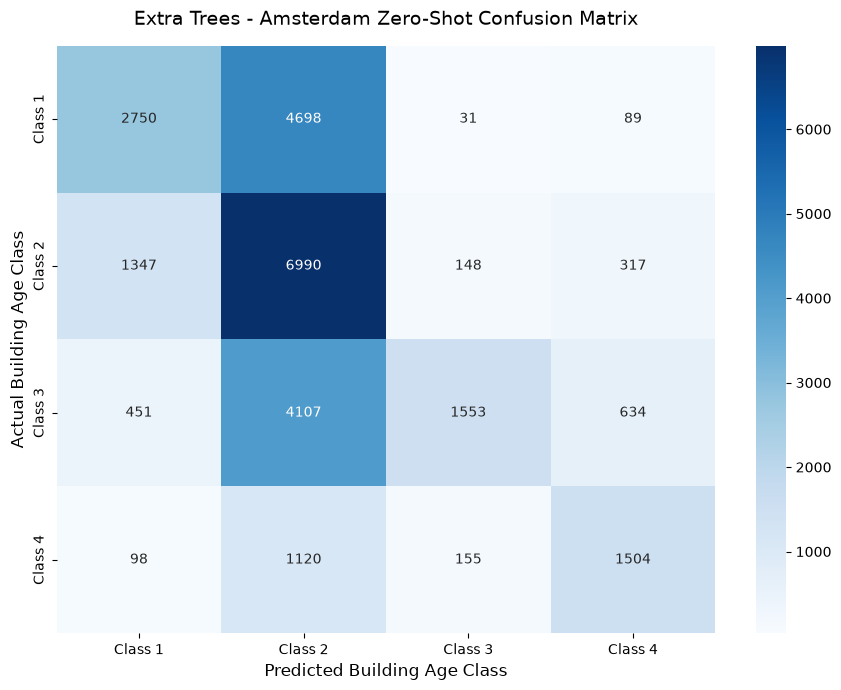

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Calculate confusion matrix
cm_et = confusion_matrix(y_amsterdam, y_pred_ams_et)

# Plot confusion matrix
plt.figure(figsize=(9, 7))

sns.heatmap(
    cm_et,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Class 1', 'Class 2', 'Class 3', 'Class 4'],
    yticklabels=['Class 1', 'Class 2', 'Class 3', 'Class 4']
)

plt.title('Extra Trees - Amsterdam Zero-Shot Confusion Matrix',
          fontsize=14, pad=15)

plt.xlabel('Predicted Building Age Class', fontsize=12)
plt.ylabel('Actual Building Age Class', fontsize=12)

plt.tight_layout()
plt.show()

# Step 9: Prepare the few-shot experiment
One important methodological decision:

Our previous Random Forest notebook used a prototype classifier for few-shot learning. That method does not actually use the Random Forest algorithm to make its predictions.

Since we are comparing algorithms, I recommend a different approach:
1. Take a small labelled sample from Amsterdam for each class.
2. Combine those samples with the Madrid training data.
3. Retrain the chosen algorithm on the combined dataset.
4. Evaluate it on the remaining Amsterdam pixels.
5. Repeat the experiment with different random samples.
This way, Extra Trees itself performs the few-shot classification.

We will initially test 5, 10, 25, 50, 100 and 200 labelled pixels per class.

Before proceeding, let's prepare the sample sizes.

In [12]:
# Few-shot sample sizes per class
SHOT_SIZES = [5, 10, 25, 50, 100, 200]

# Number of repetitions
N_REPEATS = 5

# Display experiment configuration
print("EXTRA TREES - FEW-SHOT CONFIGURATION")
print("-------------------------------------")
print("Sample sizes per class:", SHOT_SIZES)
print("Number of repetitions:", N_REPEATS)
print("Number of classes:", len(np.unique(y_amsterdam)))
print("Random seed:", RANDOM_STATE)

EXTRA TREES - FEW-SHOT CONFIGURATION
-------------------------------------
Sample sizes per class: [5, 10, 25, 50, 100, 200]
Number of repetitions: 5
Number of classes: 4
Random seed: 42


# Step 10: Create Amsterdam support and test samples
Now we need to divide Amsterdam pixels into two groups:
- Support set: A small labelled sample used to adapt Extra Trees.
- Query/test set: The remaining pixels used to evaluate the adapted model.
We will sample equally from all four age classes.

In [13]:
# Prepare Amsterdam labels
y_ams = np.asarray(y_amsterdam)

# Store the few-shot splits
few_shot_splits = {}

# Random generator for reproducibility
rng = np.random.default_rng(RANDOM_STATE)

classes = np.unique(y_ams)

for n in SHOT_SIZES:

    few_shot_splits[n] = []

    for repeat in range(N_REPEATS):

        support_indices = []

        # Select n labelled pixels from each class
        for cls in classes:

            class_indices = np.where(y_ams == cls)[0]

            selected = rng.choice(
                class_indices,
                size=n,
                replace=False
            )

            support_indices.extend(selected)

        # Convert support indices to array
        support_indices = np.array(support_indices)

        # Remaining pixels become the test set
        test_indices = np.setdiff1d(
            np.arange(len(y_ams)),
            support_indices
        )

        few_shot_splits[n].append({
            'support_indices': support_indices,
            'test_indices': test_indices
        })

print("Amsterdam few-shot splits created successfully!")
print("-----------------------------------------------")

for n in SHOT_SIZES:
    support_count = len(few_shot_splits[n][0]['support_indices'])
    test_count = len(few_shot_splits[n][0]['test_indices'])

    print(
        f"{n:3d} samples/class: "
        f"{support_count:4d} support pixels | "
        f"{test_count:5d} test pixels"
    )

Amsterdam few-shot splits created successfully!
-----------------------------------------------
  5 samples/class:   20 support pixels | 25972 test pixels
 10 samples/class:   40 support pixels | 25952 test pixels
 25 samples/class:  100 support pixels | 25892 test pixels
 50 samples/class:  200 support pixels | 25792 test pixels
100 samples/class:  400 support pixels | 25592 test pixels
200 samples/class:  800 support pixels | 25192 test pixels


# Step 11: Inspect the preprocessed file

In [14]:
# Inspect the contents of the preprocessed dataset

print("AVAILABLE DATASET KEYS")
print("----------------------")

for key, value in data.items():
    print(f"{key}: {type(value).__name__}")

AVAILABLE DATASET KEYS
----------------------
X_madrid: ndarray
y_madrid: ndarray
X_amsterdam: ndarray
y_amsterdam: ndarray
feature_names: list
scaler: StandardScaler
pixel_ids_madrid: ndarray
pixel_ids_amsterdam: ndarray
feat_groups: dict


# Step 12: Check the original data files
Before deciding how to handle the class-boundary difference, let's inspect whether the original datasets are available.

In [15]:
import os

print("AVAILABLE DATA FILES")
print("--------------------")

for folder in ['./data', './data/preprocessed']:
    print(f"\nFolder: {folder}")

    if os.path.exists(folder):
        for filename in os.listdir(folder):
            print(filename)
    else:
        print("Folder not found")

AVAILABLE DATA FILES
--------------------

Folder: ./data
preprocessed
madrid_data_saved.parquet
amsterdam_data.parquet
amsterdam_data_saved.parquet
madrid_train.parquet

Folder: ./data/preprocessed
Preprocessed_data.pkl


In [16]:
# Load original datasets
df_madrid = pd.read_parquet('./data/madrid_train.parquet')
df_amsterdam = pd.read_parquet('./data/amsterdam_data.parquet')

# Inspect construction-year information
print("MADRID")
print("-------")
print("Columns containing 'year':",
      [col for col in df_madrid.columns if 'year' in col.lower()])

print("\nAMSTERDAM")
print("---------")
print("Columns containing 'year':",
      [col for col in df_amsterdam.columns if 'year' in col.lower()])

MADRID
-------
Columns containing 'year': ['year', 'weighted_mean_year']

AMSTERDAM
---------
Columns containing 'year': ['year', 'weighted_mean_year']


In [17]:
# Get one construction-year value per geographical pixel
madrid_years = (
    df_madrid.groupby(['px_key', 'py_key'])['weighted_mean_year']
    .first()
)

amsterdam_years = (
    df_amsterdam.groupby(['px_key', 'py_key'])['weighted_mean_year']
    .first()
)

# Display descriptive statistics
print("MADRID CONSTRUCTION YEARS")
print(madrid_years.describe())

print("\nAMSTERDAM CONSTRUCTION YEARS")
print(amsterdam_years.describe())

# Check missing values
print("\nMISSING CONSTRUCTION YEARS")
print("Madrid:", madrid_years.isna().sum())
print("Amsterdam:", amsterdam_years.isna().sum())

MADRID CONSTRUCTION YEARS
count    76263.000000
mean      1980.745605
std         25.268738
min       1850.000000
25%       1965.000000
50%       1980.945435
75%       2002.173950
max       2021.000000
Name: weighted_mean_year, dtype: float64

AMSTERDAM CONSTRUCTION YEARS
count    25992.000000
mean      1964.393311
std         34.726749
min       1850.000000
25%       1934.000000
50%       1971.000000
75%       1993.000000
max       2016.000000
Name: weighted_mean_year, dtype: float64

MISSING CONSTRUCTION YEARS
Madrid: 0
Amsterdam: 0


In [18]:
# Original Madrid labels
original_madrid_labels = y_madrid.copy()

# Create harmonised Madrid labels
harmonised_madrid_labels = pd.cut(
    madrid_years,
    bins=[-np.inf, 1945, 1984, 2004, np.inf],
    labels=[1, 2, 3, 4],
    right=True
).astype(int)

# Compare original and harmonised labels
comparison = pd.DataFrame({
    'Original': original_madrid_labels,
    'Harmonised': harmonised_madrid_labels.values
})

print("MADRID CLASS COMPARISON")
print("-----------------------")

print(pd.crosstab(
    comparison['Original'],
    comparison['Harmonised'],
    rownames=['Original class'],
    colnames=['Harmonised class']
))

print("\nNumber of pixels with changed labels:",
      (comparison['Original'] != comparison['Harmonised']).sum())

print("Total Madrid pixels:", len(comparison))

MADRID CLASS COMPARISON
-----------------------
Harmonised class     1      2      3      4
Original class                             
1                 5344   8450      0      0
2                    0  27152      0      0
3                    0      0  18672      0
4                    0      0      0  16645

Number of pixels with changed labels: 8450
Total Madrid pixels: 76263


In [19]:
df_madrid.groupby(['px_key', 'py_key'])['weighted_mean_year'].first()

px_key  py_key
14194   149671    2014.000000
14196   149670    2014.000000
14259   149645    1950.000000
14268   149501    1920.000000
14302   149354    1977.178589
                     ...     
15169   149313    2008.000000
15170   149289    2008.000000
        149313    2008.000000
15171   149289    2008.000000
        149314    2008.000000
Name: weighted_mean_year, Length: 76263, dtype: float32

In [20]:
# Inspect pixel IDs and their corresponding geographical keys

print("PREPROCESSED MADRID PIXEL IDs")
print(pixel_ids_madrid[:10])

print("\nORIGINAL MADRID PIXEL KEYS")
print(madrid_years.index[:10].tolist())

print("\nNUMBER OF PIXELS")
print("Preprocessed:", len(pixel_ids_madrid))
print("Original:", len(madrid_years))

PREPROCESSED MADRID PIXEL IDs
[[ 14194 149671]
 [ 14196 149670]
 [ 14259 149645]
 [ 14268 149501]
 [ 14302 149354]
 [ 14302 149355]
 [ 14303 149353]
 [ 14303 149356]
 [ 14303 149357]
 [ 14303 149365]]

ORIGINAL MADRID PIXEL KEYS
[(14194, 149671), (14196, 149670), (14259, 149645), (14268, 149501), (14302, 149354), (14302, 149355), (14303, 149353), (14303, 149356), (14303, 149357), (14303, 149365)]

NUMBER OF PIXELS
Preprocessed: 76263
Original: 76263
